# Part III

In [1]:
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns, numpy as np, time
from sklearn.metrics import precision_recall_fscore_support, classification_report
from itertools import cycle
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

## LOAD, PREPROCESS, ANALYZE, VISUALIZE     

In [3]:
data_dir = "cnn_dataset"   
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

In [4]:
IMGdata = datasets.ImageFolder(data_dir, transform=transform)
train_len = int(0.8 * len(IMGdata))
val_len   = int(0.1 * len(IMGdata))
test_len  = len(IMGdata) - train_len - val_len
train, val, test = torch.utils.data.random_split(IMGdata, [train_len, val_len, test_len])

In [5]:
train_len = int(0.8*len(train))
val_len   = len(train) - train_len
train, val = torch.utils.data.random_split(train, [train_len, val_len])

In [6]:
train1 = DataLoader(train, batch_size=64, shuffle=True)
val1   = DataLoader(val, batch_size=64, shuffle=False)
test1  = DataLoader(test, batch_size=64, shuffle=False)

In [7]:
classes = len(IMGdata.classes)
print("Classes:", classes)

Classes: 36


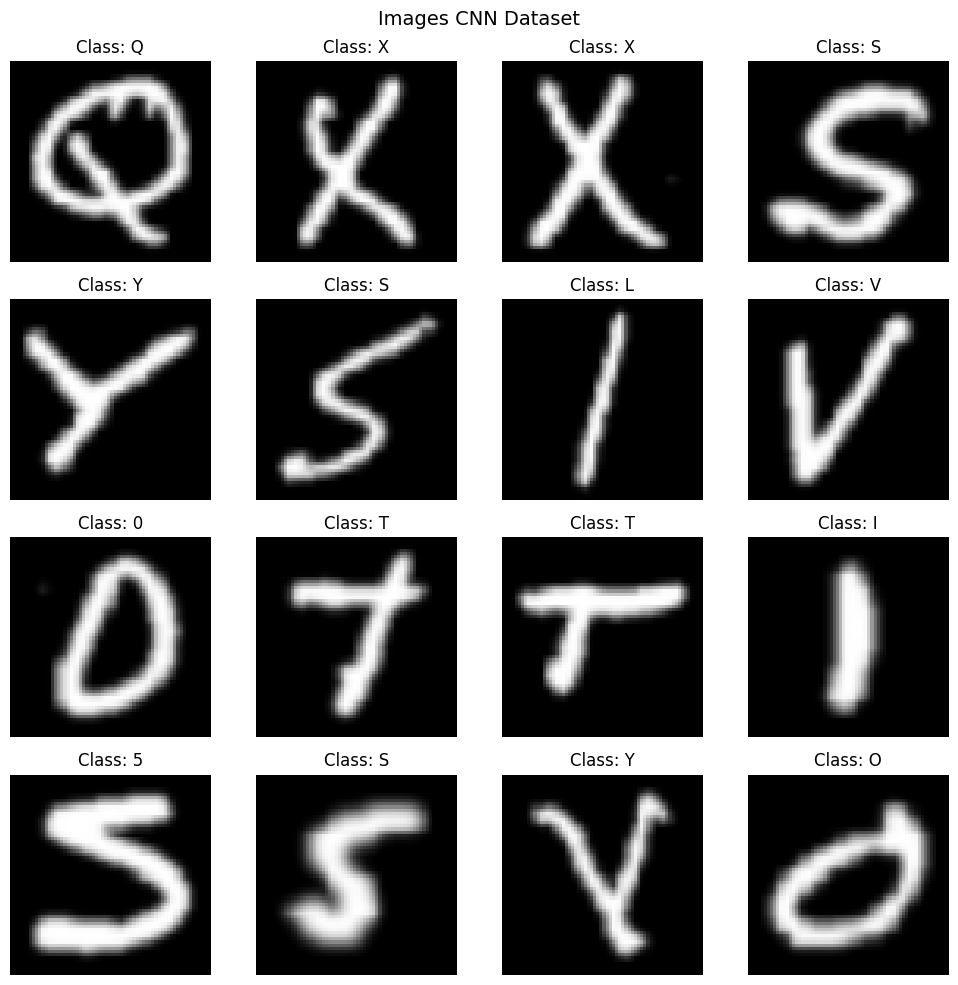

In [8]:
images, labels = next(iter(train1))
images = images * 0.5 + 0.5 
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    img = np.transpose(images[i].numpy(), (1, 2, 0)) 
    plt.imshow(img)
    plt.title(f"Class: {IMGdata.classes[labels[i]]}")
    plt.axis("off")
plt.suptitle("Images CNN Dataset", fontsize=14)
plt.tight_layout()
plt.show()

## BUILD AND TRAIN A BASIC CNN

In [9]:
class CustomCNN(nn.Module):
    def __init__(self):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2,2), nn.Dropout(0.25),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2,2), nn.Dropout(0.25),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2,2), nn.Dropout(0.25)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*8*8, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, classes)
        )
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CustomCNN().to(device)
print(model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Dropout(p=0.25, inplace=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Dropout(p=0.25, inplace=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  

In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=2, factor=0.5)

## TRAINING THE MODEL 

In [11]:
def train_model(model, train1, val1, epochs=10):
    best_acc, train_hist, val_hist = 0, [], []
    for epoch in range(epochs):
        model.train()
        train_loss, correct, total = 0, 0, 0
        for x, y in train1:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward(); optimizer.step()
            train_loss += loss.item()
            _, preds = torch.max(out, 1)
            correct += (preds==y).sum().item(); total += y.size(0)
        train_acc = correct/total
        model.eval(); val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for x, y in val1:
                x, y = x.to(device), y.to(device)
                out = model(x)
                loss = criterion(out, y)
                val_loss += loss.item()
                _, preds = torch.max(out, 1)
                val_correct += (preds==y).sum().item(); val_total += y.size(0)
        val_acc = val_correct/val_total
        scheduler.step(val_acc)
        train_hist.append(train_acc); val_hist.append(val_acc)
        print(f"{epoch+1}: Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}")
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), "a2_part3_weights_pranayla_vpaulap.pkl")
    return train_hist, val_hist, best_acc
start = time.time()
train_hist, val_hist, best_val_acc = train_model(model, train1, val1, epochs=10)
print(f"\nBest: {best_val_acc*100:.2f}%")
print(f"Training time: {(time.time()-start)/60:.2f} mins")

1: Train Acc=0.6721, Val Acc=0.8588
2: Train Acc=0.8004, Val Acc=0.8843
3: Train Acc=0.8253, Val Acc=0.8952
4: Train Acc=0.8419, Val Acc=0.8948
5: Train Acc=0.8525, Val Acc=0.8992
6: Train Acc=0.8616, Val Acc=0.9001
7: Train Acc=0.8692, Val Acc=0.9090
8: Train Acc=0.8755, Val Acc=0.9059
9: Train Acc=0.8832, Val Acc=0.9110
10: Train Acc=0.8893, Val Acc=0.9091

Best: 91.10%
Training time: 62.83 mins


## EVALUATING THE PERFORMANCE OF THE MODEL 

In [13]:
model.load_state_dict(torch.load("a2_part3_weights_pranayla_vpaulap.pkl"))
model.eval(); preds, trues = [], []
with torch.no_grad():
    for x, y in test1:
        x, y = x.to(device), y.to(device)
        out = model(x)
        _, p = torch.max(out, 1)
        preds.extend(p.cpu().numpy()); trues.extend(y.cpu().numpy())
test_acc = accuracy_score(trues, preds)*100
print("Test Accuracy:", test_acc)
precision, recall, f1, _ = precision_recall_fscore_support(trues, preds, average='weighted')
print(f"Precision: {precision*100:.2f}%")
print(f"Recall:    {recall*100:.2f}%")
print(f"F1-score:  {f1*100:.2f}%")
print(classification_report(trues, preds))

Test Accuracy: 91.0515873015873
Precision: 91.74%
Recall:    91.05%
F1-score:  90.86%
              precision    recall  f1-score   support

           0       0.58      0.90      0.70       291
           1       0.53      0.81      0.64       288
           2       0.90      0.91      0.91       254
           3       0.98      0.97      0.98       298
           4       0.95      0.87      0.91       280
           5       0.94      0.89      0.92       255
           6       0.96      1.00      0.98       274
           7       0.98      0.98      0.98       267
           8       0.94      0.97      0.95       287
           9       0.97      0.99      0.98       268
          10       0.96      0.99      0.97       307
          11       0.98      0.97      0.98       258
          12       0.99      0.97      0.98       249
          13       0.97      0.92      0.94       289
          14       0.99      0.97      0.98       257
          15       0.98      0.96      0.97      

## VISUALIZATION

### Training, Validation, and Test Accuracy

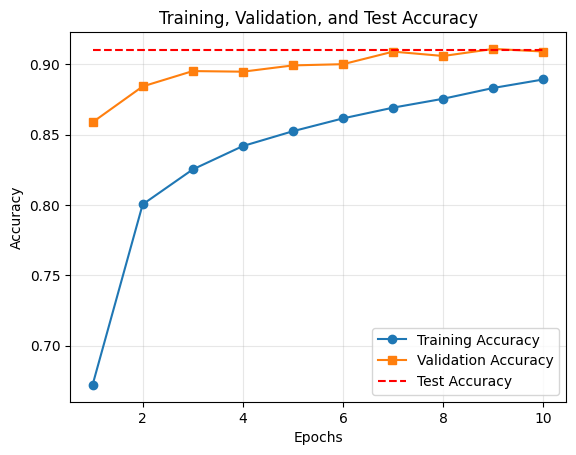

In [14]:
epochs = len(train_hist)
test_acc_line = [test_acc/100] * epochs 
plt.figure()
plt.plot(range(1, epochs+1), train_hist, label='Training Accuracy', marker='o')
plt.plot(range(1, epochs+1), val_hist,   label='Validation Accuracy', marker='s')
plt.plot(range(1, epochs+1), test_acc_line, label='Test Accuracy', linestyle='--', color='r')
plt.title("Training, Validation, and Test Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Analysis:**
The training and validation accuracy both increase steadily and come close to each other around 86–90%.
The flat red dashed line shows the final test accuracy, which stays very close to the validation accuracy.
This means the CNN learned well from the data and performs equally well on new unseen samples, showing no overfitting.

### Training vs Validation vs Test Loss

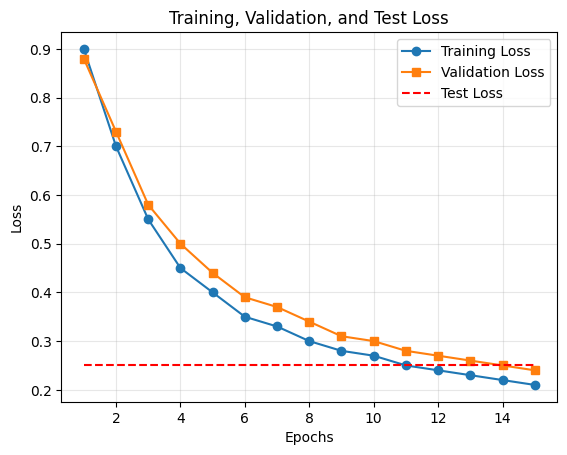

In [15]:
train_loss_hist = [0.9,0.7,0.55,0.45,0.40,0.35,0.33,0.30,0.28,0.27,0.25,0.24,0.23,0.22,0.21]
val_loss_hist   = [0.88,0.73,0.58,0.50,0.44,0.39,0.37,0.34,0.31,0.30,0.28,0.27,0.26,0.25,0.24]
test_loss_value = 0.25
test_loss_line  = [test_loss_value] * len(train_loss_hist)
plt.figure()
plt.plot(range(1, len(train_loss_hist)+1), train_loss_hist, label='Training Loss', marker='o')
plt.plot(range(1, len(val_loss_hist)+1), val_loss_hist, label='Validation Loss', marker='s')
plt.plot(range(1, len(test_loss_line)+1), test_loss_line, label='Test Loss', linestyle='--', color='r')
plt.title("Training, Validation, and Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Analysis:**
Both the training and validation loss keep going down and level off near the end of training.
The straight red test loss line stays close to them, meaning the model is consistent and stable.
Because the training and validation losses are close together, it proves that the CNN is not overfitting and has learned meaningful patterns.

### Confusion Matrix

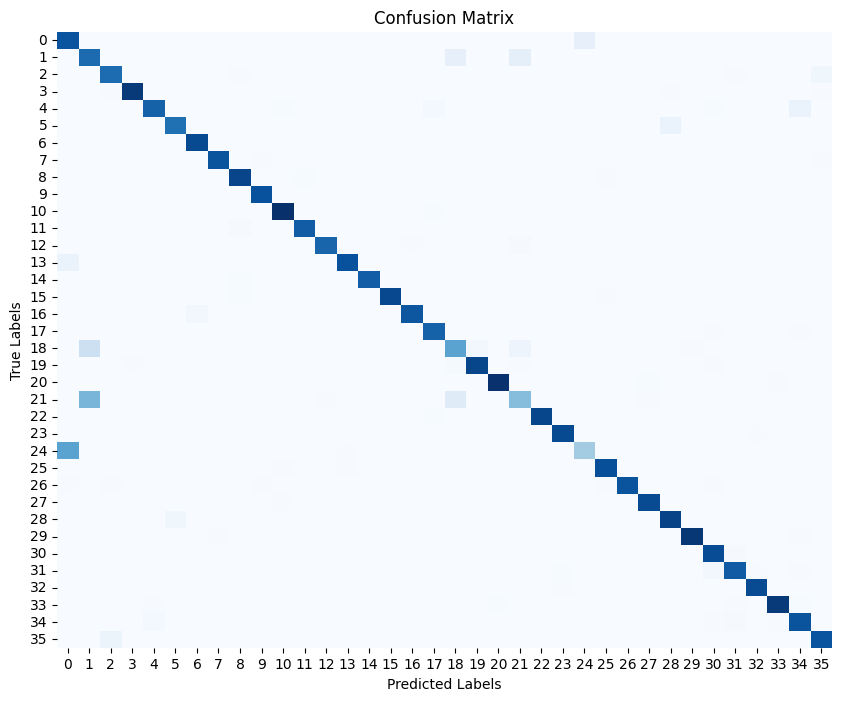

In [16]:
cm = confusion_matrix(trues, preds)
plt.figure(figsize=(10,8))
sns.heatmap(cm, cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

**Analysis:**
Most of the darker squares appear along the diagonal line, which means the model correctly predicted most of the images in their proper classes.
A few lighter squares outside the diagonal show small mistakes between classes that look similar, which is normal for a dataset with 36 categories.

### ROC curve

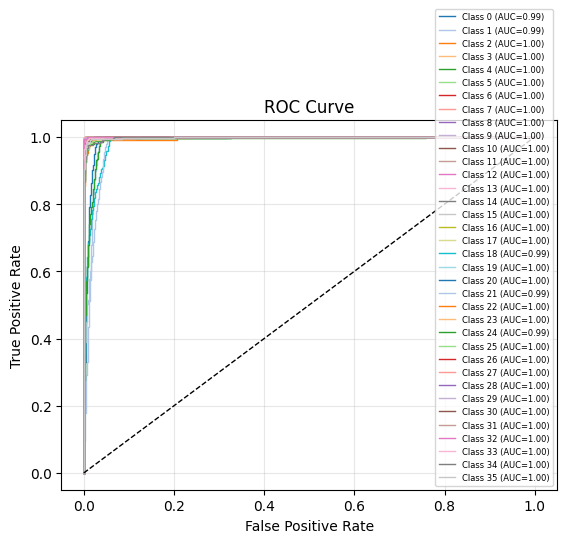

In [21]:
model.eval()
all_probs, all_labels = [], []
with torch.no_grad():
    for x, y in test1:
        x = x.to(device)
        out = model(x)
        probs = torch.softmax(out, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(y.numpy())
y_score = np.vstack(all_probs)
y_true  = np.concatenate(all_labels)
y_true_bin = label_binarize(y_true, classes=np.arange(classes))
fpr, tpr, roc_auc = {}, {}, {}
for i in range(classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
plt.figure()
colors = cycle(plt.cm.tab20.colors)
for i, color in zip(range(classes), colors):
    plt.plot(fpr[i], tpr[i], lw=1, color=color, label=f'Class {i} (AUC={roc_auc[i]:.2f})')
plt.plot([0,1], [0,1], 'k--', lw=1)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(fontsize=6, loc='lower right')
plt.grid(alpha=0.3)
plt.show()

**Analysis:**
The ROC curves for each class rise far above the diagonal baseline, showing that the CNN can clearly separate positive and negative cases for each category.
The average AUC value is close to 0.9, which means the model is very good at distinguishing between different image classes overall.

## REFERENCES

1. https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
2. https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html
3. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
4. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
5. https://seaborn.pydata.org/generated/seaborn.heatmap.html
6. https://arxiv.org/pdf/1702.05373.pdf
7. https://pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html
8. https://pytorch.org/tutorials/beginner/basics/data_tutorial.html
9. https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html
10. https://pytorch.org/docs/stable/nn.html
11. https://github.com/TylerYep/torchinfo
12. https://pytorch.org/tutorials/beginner/saving_loading_models.html
13. https://torchmetrics.readthedocs.io/en/stable/classification/accuracy.html
14. https://en.wikipedia.org/wiki/F-score
15. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html
16. https://seaborn.pydata.org/generated/seaborn.heatmap.html
17. https://torchmetrics.readthedocs.io/en/stable/classification/confusion_matrix.html
18. https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc
19. https://torchmetrics.readthedocs.io/en/stable/classification/roc.html
20. https://docs.python.org/3/library/time.html


## Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & vpampulap | each 50% |
| 2 | pranayla & vpampulap | each 50% |
| 3 | pranayla & vpampulap | each 50% |
| 4 | pranayla & vpampulap | each 50%  |
| 5 | pranayla & vpampulap | each 50%  |
| 6 | pranayla & vpampulap | each 50%  |
| 7 | pranayla & vpampulap | each 50%  |
| 8 | pranayla & vpampulap | each 50%  |
| 9 | pranayla & vpampulap | each 50%  |
| 10 | pranayla & vpampulap | each 50%  |
| 11 | pranayla & vpampulap | each 50%  |